# Ga for tuning the h-p

In this notebook I will tune the size and number of the hidden layers.
The difference from the notebook ga for tuning 2, is that the possible number of units per layer are real numbers chosen in an interval, instead of a fixed number of classes. 

## The NN

In [1]:
# Libs

import torch # the main pytorch library
from torch import nn # the sub-library containing neural networks
from torch.utils.data import DataLoader, Subset # an object that generates batches of data for training/testing
from torchvision import datasets # popular datasets, architectures and common image transformations
from torchvision.transforms import ToTensor # an easy way to convert PIL images to Tensors

import numpy as np # NumPy, the python array library
import random # for generating random numbers
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split


In [2]:
# Set seeds

SEED = 0 # seed for reproducibility

random.seed(SEED) # set the seed for random numbers
np.random.seed(SEED) # set the seed for numpy arrays

In [3]:
# Download training data
# Build validation data
# Download test data

# Parameters
validation_ratio = 0.2

# Download training data from open datasets
training_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=True,  # this is the training data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


# Split dataset into training and validation sets
# train and validation data
num_samples = len(training_data)
num_validation_samples = int(validation_ratio * num_samples)
num_training_samples = num_samples - num_validation_samples

# First num_training_samples are for training 
# Last num_validation_samples are for validation
train_data = Subset(training_data, range(num_training_samples))
validation_data = Subset(training_data, range(num_training_samples, num_samples))



# Download test data from open datasets
test_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=False,  # this is the test data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


In [4]:
# Define data loader (specifing batch size)

batch_size = 64 # the size of input data took for one iteration

# Create data loaders.
# Create data loaders
train_dataloader = DataLoader(train_data, batch_size=batch_size)
validation_dataloader = DataLoader(validation_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

# N is batch size; 
# C is number of channels;
# H is height of image; 
# W is width of image
for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in validation_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break



Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [5]:
# Set the device 
device = ( # check if gpu is available
    "cuda"
    if torch.cuda.is_available() # use gpu
    else "mps" # use mps
    if torch.backends.mps.is_available() # use mps
    else "cpu" # use cpu
)
print(f"Using {device} device\n")

Using cpu device



In [6]:
# A model in which you can specify: 
# the number of hidden units,
# the activation function,
# whether to initialize the weights or not

class flexible_NN_units(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_size1 = 512,
                 hidden_size2 = 512,
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(input_size, hidden_size1), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            self.activation_function,  # activation function
            nn.Linear(hidden_size1, hidden_size2), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            self.activation_function, # activation function
            nn.Linear(hidden_size2, output_size) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)



# A model in which you can specify: 
# the number of hidden layers and units,
# the activation function,
# whether to initialize the weights or not


class flexible_NN_layers(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_sizes = [512,512],
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()

        # Create a list to hold the layers
        layers = []
        previous_size = input_size

        # Add hidden layers dynamically
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(self.activation_function)
            previous_size = hidden_size
        layers.append(nn.Linear(previous_size, output_size)) # Add the final output layer

        # Create a sequential container with the layers
        # You shoould pass a list of layers to the Sequential container, one by one. 
        # You can do this by using the * operator to unpack the list of layers
        # This is done to avoid of passing a list of layers to the Sequential container (that is not correct)
        self.linear_relu_stack = nn.Sequential(*layers)
      
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)

In [7]:
# Train and test functions

def train(dataloader, model, loss_fn, optimizer): # create a training function
    size = len(dataloader.dataset) # get the size of the dataset
    model.train() # set the model to training mode
    train_loss = 0.0 # initialise the training loss
    for batch, (X, y) in enumerate(dataloader): # iterate over the data
        X, y = X.to(device), y.to(device) # send the input data to the device

        # Compute prediction error
        pred = model(X) # get the model's prediction
        loss = loss_fn(pred, y) # compute the loss (between the model's prediction and the actual value)

        # Backpropagation
        loss.backward() # backpropagate the loss
        optimizer.step() # adjust the model parameters
        optimizer.zero_grad() # reset the gradients

        train_loss += loss.item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X) # get the loss and the current batch
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    
    train_loss /= len(dataloader)
    return train_loss




def test(dataloader, model, loss_fn): # create a test function
    size = len(dataloader.dataset)
    num_batches = len(dataloader) # get the number of batches
    model.eval() # set the model to evaluation mode (test correspondece of model.train())
    test_loss, correct = 0, 0 # initialise the test loss and the number of correct predictions
    with torch.no_grad(): # disable gradient calculation
        for X, y in dataloader: # iterate over the data
            X, y = X.to(device), y.to(device) # send the input data to the device
            pred = model(X) # get the model's prediction
            test_loss += loss_fn(pred, y).item() # compute the loss
            correct += (pred.argmax(1) == y).type(torch.float).sum().item() # compute the number of correct predictions
    test_loss /= num_batches # compute the average loss
    correct /= size # compute the accuracy
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss, 100*correct



# All in one function

def train_and_test_model(epochs, model, loss_fn, optimizer, train_dataloader, test_dataloader):
    train_loss_history = []
    test_loss_history = []
    accuracy_history = []

    for t in range(epochs):
        print(f"Epoch {t+1}\n-------------------------------")
        train_loss = train(train_dataloader, model, loss_fn, optimizer)
        test_loss, accuracy = test(test_dataloader, model, loss_fn)

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        accuracy_history.append(accuracy)

    print("Done!")
    return train_loss_history, test_loss_history, accuracy_history


## The EA 

### Structures

In [67]:
class Individual:
    def __init__(self, gene, fitness=0.0):
        """
        Initialize an individual with a gene, solution, and fitness.
        
        Parameters:
        gene (float): The value in the space of the gene.
        solution (Any): The value in the space of the solution.
        fitness (float): The fitness value of the individual.
        """
        self.gene = gene
        self.solution = self.from_gene_to_solution(gene)
        self.fitness = fitness
    
    def from_gene_to_solution(self, genotype):
        """
        Convert the gene to a solution.
        """
        # For all element in the list of the genes, the solution is the list of the integer raund of the gene
        return [round(g) for g in genotype]


    
    def __repr__(self):
        return f"Gene: {self.gene}, Solution: {self.solution}, Fitness: {self.fitness}"

# Example usage:
individual1 = Individual(gene=[16.6,16])
individual2 = Individual(gene=[32,32.4])

print(f"Individual 1: {individual1}")
print(f"Individual 2: {individual2}")


Individual 1: Gene: [16.6, 16], Solution: [17, 16], Fitness: 0.0
Individual 2: Gene: [32, 32.4], Solution: [32, 32], Fitness: 0.0


### Initialization

In [68]:
def initialization(population_size=10, number_of_layers_interval=[1, 5], number_of_units_interval=[10, 600]):
    genes = []
    
    for _ in range(population_size):
        num_layers = random.randint(number_of_layers_interval[0], number_of_layers_interval[1])
        gene = [random.randint(number_of_units_interval[0], number_of_units_interval[1]) for _ in range(num_layers)]
        genes.append(gene)
    
    individuals = [Individual(gene=g) for g in genes]
    return individuals

# Example usage:False
population_size = 5
population = initialization(population_size)

for individual in population:
    print(individual)

Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 0.0
Gene: [179], Solution: [179], Fitness: 0.0
Gene: [75, 275, 171, 467], Solution: [75, 275, 171, 467], Fitness: 0.0
Gene: [508, 584, 10, 49, 516], Solution: [508, 584, 10, 49, 516], Fitness: 0.0
Gene: [329, 488, 61], Solution: [329, 488, 61], Fitness: 0.0


### Fitness assessment

In [69]:
def fitness_evaluation(
        individual,
        training_data,
        validation_data,
        num_epochs_per_evaluation=5,
        lr = 0.0096,
        input_size = 28*28,
        output_size = 10,
        activation_function = nn.LeakyReLU,
        initialize_weights = False
        ):

    # Set the device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Create a new model
    model = flexible_NN_layers(
        input_size=input_size,
        hidden_sizes=individual.gene,
        output_size=output_size,
        activation_function=activation_function,
        initialize_weights=initialize_weights).to(device)
    
    # Define loss function
    loss_fn = nn.CrossEntropyLoss()
    
    # Create a new optimizer with the specified learning rate
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    
    
    # Train the model for the specified number of epochs
    for _ in range(num_epochs_per_evaluation):
        model.train()
        for X, y in training_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    
    # Compute the validation loss
    model.eval()
    validation_loss = 0
    with torch.no_grad():
        for X, y in validation_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            validation_loss += loss.item()
    
    # Average validation loss over all batches
    validation_loss /= len(validation_data)
    
    return validation_loss


# Example usage:
individual = population[0]
fitness = fitness_evaluation(
    individual,
    train_dataloader,
    validation_dataloader,
    num_epochs_per_evaluation=5)

print(f"Individual: {individual}")
print(f"Fitness of individual: {fitness}")

Individual: Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 0.0
Fitness of individual: 0.5711983841784457


In [70]:
# Assess population
def evaluate_population(
        population,
        training_data,
        validation_data,
        num_epochs_per_evaluation=5,
        lr = 0.0096,
        input_size = 28*28,
        output_size = 10,
        activation_function = nn.LeakyReLU,
        initialize_weights = False):
    
    for individual in population:
        individual.fitness = fitness_evaluation(
            individual,
            training_data,
            validation_data,
            num_epochs_per_evaluation,
            lr,
            input_size,
            output_size,
            activation_function,
            initialize_weights)
    

# Example usage:
evaluate_population(
    population,
    train_dataloader,
    validation_dataloader,
    num_epochs_per_evaluation=1) # 1 is just for testing if it works (at least 10 is suggested)

for individual in population:
    print(individual)

Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Gene: [179], Solution: [179], Fitness: 0.8084023877027187
Gene: [75, 275, 171, 467], Solution: [75, 275, 171, 467], Fitness: 1.5422202970119232
Gene: [508, 584, 10, 49, 516], Solution: [508, 584, 10, 49, 516], Fitness: 2.294869691767591
Gene: [329, 488, 61], Solution: [329, 488, 61], Fitness: 1.1633932967769338


### Selection

In [71]:
def find_best_individual(population, maximize=False):
    """
    Find the individual with the best fitness value in the population.
    
    Parameters:
    population (list): A list of Individual objects.
    
    Returns:
    Individual: The individual with the best fitness value.
    """
    if maximize:
        best_individual = max(population, key=lambda x: x.fitness)
    else:
        best_individual = min(population, key=lambda x: x.fitness)
    return best_individual

# Example usage:
best_individual = find_best_individual(population)
print(best_individual)

Gene: [179], Solution: [179], Fitness: 0.8084023877027187


In [72]:
# Tournament selection
# number_of_selected: The number of individuals to select.
# percentage_of_population_size: The percentage of the population size to use for the tournament.
def tournament_selection(population, number_of_selected, percentage_of_population_size):
    selected_individuals = []
    tournament_size = max(1, int(len(population) * percentage_of_population_size))

    for _ in range(number_of_selected):
        # Randomly select individuals for the tournament
        tournament_individuals = random.sample(population, tournament_size)
        
        # Select the best individual from the tournament
        best_individual = min(tournament_individuals, key=lambda ind: ind.fitness)
        
        # Ensure uniqueness
        while best_individual in selected_individuals:
            tournament_individuals = random.sample(population, tournament_size)
            best_individual = min(tournament_individuals, key=lambda ind: ind.fitness)
        
        selected_individuals.append(best_individual)

    return selected_individuals

# Example usage:
selected_individuals = tournament_selection(population, number_of_selected=2, percentage_of_population_size=0.4)

print("\nPopulation:")
for individual in population:
    print(individual)

print("\nSelected individuals:")
for individual in selected_individuals:
    print(individual)


Population:
Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Gene: [179], Solution: [179], Fitness: 0.8084023877027187
Gene: [75, 275, 171, 467], Solution: [75, 275, 171, 467], Fitness: 1.5422202970119232
Gene: [508, 584, 10, 49, 516], Solution: [508, 584, 10, 49, 516], Fitness: 2.294869691767591
Gene: [329, 488, 61], Solution: [329, 488, 61], Fitness: 1.1633932967769338

Selected individuals:
Gene: [179], Solution: [179], Fitness: 0.8084023877027187
Gene: [329, 488, 61], Solution: [329, 488, 61], Fitness: 1.1633932967769338


### Evolutionary operators 

**Crossover operators:**
- 1 point cx
- 1 point cx with mean 

1 point cx is, given aaaaa, bbbbb, takes a poin in [1,5] for instance 3 then aaa|aa, bbb|bb -> aaa|bb, bbb|aa

1 point cx with mean is, given aaaaa, bbbbb, takes a poin in [1,5] for instance 3, take the mean argument by argument of aaaaa and bbbbb giving ccccc then aaa|aa, bbb|bb -> aaa|cc, ccc|aa if aaaaa is the fittest individual. 

**Mutation operators:**
- 30 per cent ub

Take all the parents of the selection, do the mean argument by argument giving c1 c2 c3 c4 c5.
Compute the 30 percent of each ci giving di
Now, for each argument i of the individual sum a value in [-di,+di] with a probability p, do nothing otherwise. 

#### Crossover operators

In [73]:
# Description:
# aaa|aa 
# bbb|bb
# --> aaa|bb, bbb|aa
def single_point_crossover(parent1, parent2):
    gene1, gene2 = parent1.gene, parent2.gene
    if len(gene1) == 1 or len(gene2) == 1:
        return parent1, parent2  # No crossover if a parent has only one layer
    point = random.randint(1, min(len(gene1), len(gene2)) - 1)
    child_gene1 = gene1[:point] + gene2[point:]
    child_gene2 = gene2[:point] + gene1[point:]
    child1 = Individual(gene=child_gene1)
    child2 = Individual(gene=child_gene2)
    return child1, child2

# Exmaple usage
parent1 = population[0]
parent2 = population[1]
offspring1, offspring2 = single_point_crossover(parent1, parent2)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"\nOffspring2 CX: {offspring1}")
print(f"Offspring1 CX: {offspring2}")

Parent 1: Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Parent 2: Gene: [179], Solution: [179], Fitness: 0.8084023877027187

Offspring2 CX: Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Offspring1 CX: Gene: [179], Solution: [179], Fitness: 0.8084023877027187


In [74]:
def single_point_crossover_fitness_based_with_E(parent1, parent2):
    gene1, gene2 = parent1.gene, parent2.gene
    
    # Determine the fittest parent
    if parent1.fitness < parent2.fitness:
        fitter_parent = parent1
        other_parent = parent2
    else:
        fitter_parent = parent2
        other_parent = parent1

    if len(gene1) == 1 or len(gene2) == 1:
        return parent1, parent2  # No crossover if a parent has only one layer
    
    point = random.randint(1, min(len(gene1), len(gene2)) - 1)
    
    # Split genes at the crossover point
    first_part_fitter = fitter_parent.gene[:point]
    second_part_fitter = fitter_parent.gene[point:]
    
    first_part_other = other_parent.gene[:point]
    second_part_other = other_parent.gene[point:]
    
    # Compute averages for the second part of genes
    avg_second_part = [(a + b) / 2 for a, b in zip(second_part_fitter, second_part_other)]
    avg_first_part = [(a + b) / 2 for a, b in zip(first_part_fitter, first_part_other)]
    
    # Create new genes for the children
    child_gene1 = first_part_fitter + avg_second_part
    child_gene2 = avg_first_part + second_part_fitter
    
    # Create child individuals
    child1 = Individual(gene=child_gene1, fitness=None)  # Fitness can be computed later
    child2 = Individual(gene=child_gene2, fitness=None)
    
    return child1, child2

# Example usage
parent1 = population[0]
parent2 = population[1]
offspring1, offspring2 = single_point_crossover_fitness_based_with_E(parent1, parent2)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"\nOffspring1: {offspring1}")
print(f"Offspring2: {offspring2}")

Parent 1: Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Parent 2: Gene: [179], Solution: [179], Fitness: 0.8084023877027187

Offspring1: Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Offspring2: Gene: [179], Solution: [179], Fitness: 0.8084023877027187


#### Mutation operators

The integer mutation is an evolutionary operator quite complicated that i built for the case of the optimization of the number of units of a nueral network when the the genotype is a real number. 
The input is 
```python
individual, mutation_probability, mutation_range_per_layer, minimum_gene, maximum_gene
```
Given a genotype, for instance [120,130,110], a mutation probabbility, for instance 0.1 and a utation range layer for instance [30,20,10,20,20] for instance, the procedure is the following:
- Start with layer 1 (units = 120)
- With probability 0.1
  - units = units + [-30,30]
  
The, repeat for each layer. 

Moreover, 
- At the beginning, the last elements of the array [30,20,10,20,20] are removed if the len of this is larger then the len of [120,130,110].
- it is forced that each new gene must belong in [minimum_gene, maximum_gene]

In [75]:
# Description: mutation
# mutation_probability: The probability of mutation for each gene.
# mutation_range: The range of the mutation.
# minimum_gene: The minimum value of the gene.
# maximum_gene: The maximum value of the gene.
def integer_mutation(individual, mutation_probability, mutation_range_per_layer, minimum_gene, maximum_gene):
    gene = individual.gene
    mutated_gene = []

    # Shrink the mutation_range_per_layer if it is larger than the gene length
    if len(mutation_range_per_layer) > len(gene):
        mutation_range_per_layer = mutation_range_per_layer[:len(gene)]
    
    for value,i in zip(gene,range(len(gene))):
        if random.random() < mutation_probability:
            #print(f"Mutation of gene{i}:{value}, taken in {-mutation_range_per_layer[i]}, {mutation_range_per_layer[i]}")
            mutation = random.randint(-mutation_range_per_layer[i], mutation_range_per_layer[i])
            mutated_value = value + mutation
            if mutated_value < minimum_gene or mutated_value > maximum_gene: # Check if the mutated value is within the bounds
                if mutated_value < minimum_gene:
                    mutated_value = minimum_gene
                else:
                    mutated_value = maximum_gene
            mutated_gene.append(mutated_value)
        else:
            mutated_gene.append(value)
    
    return Individual(gene=mutated_gene)

# Example of usage 
individual = population[0]
mutation_probability = 0.5
mutation_range = [30,30,30,30,30,30]
minimum_gene = 10
maximum_gene = 600
mutated_individual = integer_mutation(individual, mutation_probability, mutation_range, minimum_gene, maximum_gene)

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")
    

Individual: Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Mutated individual: Gene: [42, 391, 600, 408], Solution: [42, 391, 600, 408], Fitness: 0.0


In [76]:
# Mutation pre process 
def integer_mutation_preprocess(parents, percentage_of_integer_mutation):
    max_gene_length = max(len(parent.gene) for parent in parents)  # Choose the gene with the largest number of layers
    mutation_ub_per_layer = [
        round(np.mean([parent.gene[i] for parent in parents if i < len(parent.gene)]))
        for i in range(max_gene_length)  # Ensure all parents have the same length gene sequence
    ]  # Define the mutation_range_per_layer list as the mean of the units of all the parents for each layer 
    for i in range(len(mutation_ub_per_layer)):
        mutation_ub_per_layer[i] = round(mutation_ub_per_layer[i] * percentage_of_integer_mutation)
    return mutation_ub_per_layer

# Example usage
parents = population[0:3]
percentage_of_integer_mutation = 0.2
mutation_ub_per_layer = integer_mutation_preprocess(parents, percentage_of_integer_mutation)

print(f"\nParents:")
for parent in parents:
    print(parent)
print(f"\nMutation range per layer:")
for r in mutation_ub_per_layer:
    print(r)

# Application 
individual = population[0]
mutation_probability = 1
minimum_gene = 10
maximum_gene = 600
mutated_individual = integer_mutation(individual, mutation_probability, mutation_ub_per_layer, minimum_gene, maximum_gene)

print(f"\nIndividual: {individual}")
print(f"Mutated individual: {mutated_individual}")



Parents:
Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Gene: [179], Solution: [179], Fitness: 0.8084023877027187
Gene: [75, 275, 171, 467], Solution: [75, 275, 171, 467], Fitness: 1.5422202970119232

Mutation range per layer:
20
70
76
90

Individual: Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Mutated individual: Gene: [22, 486, 563, 514], Solution: [22, 486, 563, 514], Fitness: 0.0


In [77]:
# This mutation removes a gene
def shrink_mutation(individual):
    mutated_gene = individual.gene.copy()
    if len(mutated_gene) <= 1:
        return Individual(gene=mutated_gene)  # No mutation if there's only one layer
    
    index = random.randint(0, len(mutated_gene) - 1)
    mutated_gene.pop(index)
    
    return Individual(gene=mutated_gene)

# Example usage
individual = population[0]
mutated_individual = shrink_mutation(individual)

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")

Individual: Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Mutated individual: Gene: [42, 591, 438], Solution: [42, 591, 438], Fitness: 0.0


In [78]:
# This mutation adds a gene
def grow_mutation(individual, new_layer_range, position='random'):
    mutated_gene = individual.gene.copy()
    
    if position == 'beginning':
        index = 0
    elif position == 'end':
        index = len(mutated_gene)
    else:  # Default to inserting at a random position
        index = random.randint(0, len(mutated_gene))
    
    new_layer_size = random.randint(new_layer_range[0], new_layer_range[1])
    mutated_gene.insert(index, new_layer_size)
    
    return Individual(gene=mutated_gene)

# Example usage
individual = population[0]
y = max(individual.gene); new_layer_range = [10, y] # New layer range as a list from [10,y] where y is the maximum single gene of the individual
mutated_individual = grow_mutation(individual, new_layer_range)


print(f"New layer range: {new_layer_range}")
print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")


New layer range: [10, 591]
Individual: Gene: [42, 421, 591, 438], Solution: [42, 421, 591, 438], Fitness: 1.5154186385743162
Mutated individual: Gene: [42, 421, 296, 591, 438], Solution: [42, 421, 296, 591, 438], Fitness: 0.0


### Update population

In [80]:
def create_offsprings(
    parents, 
    offsprings_size,
    crossover_operator,
    integer_mutation_probability_per_layer,
    percentage_of_integer_mutation, # try [20,30]
    grow_shrink_mutation_operator_check = False,
    grow_shrink_mutation_probability = 0.5, # probability of applying grow or shrink mutation
    minimum_gene = 10,
    maximum_gene = 600
    ):
    """
    Create a new population by applying crossover and mutation on the parents.
    
    Parameters:
    parents (list of Individual): The list of parent individuals.
    population_size (int): The desired size of the new population.
    mutation_probability (float): The probability of applying mutation to an offspring.
    
    Returns:
    list of Individual: The new population of individuals.
    """
    offsprings = []
    
    # Prepare data for the mutation operator 
    mutation_ub_per_layer = integer_mutation_preprocess(parents, percentage_of_integer_mutation)

    while len(offsprings) < offsprings_size:
        # Select two random parents for crossover
        parent1, parent2 = np.random.choice(parents, 2, replace=False)

        # Apply crossover
        offspring1, offspring2 = crossover_operator(parent1, parent2)
        if grow_shrink_mutation_operator_check:
            if random.random() < grow_shrink_mutation_probability/2:
                offspring1 = grow_mutation(offspring1)
            else:
                offspring1 = shrink_mutation(offspring1)
            if random.random() < grow_shrink_mutation_probability/2:
                offspring2 = grow_mutation(offspring2)
            else:
                offspring2 = shrink_mutation(offspring2)
        offspring1 = integer_mutation(offspring1, integer_mutation_probability_per_layer, mutation_ub_per_layer, minimum_gene, maximum_gene)
        offspring2 = integer_mutation(offspring2, integer_mutation_probability_per_layer, mutation_ub_per_layer, minimum_gene, maximum_gene) 

        # Add the offspring to the new population
        offsprings.append(offspring1)
        offsprings.append(offspring2)
    
    return offsprings

# Example usage:
parents = selected_individuals
offsprings_size = 3
crossover_operator = single_point_crossover_fitness_based_with_E
integer_mutation_probability_per_layer = 0.5
percentage_of_integer_mutation = 0.2

offsprings = create_offsprings(
    parents = selected_individuals,
    offsprings_size = offsprings_size,
    crossover_operator=crossover_operator,
    integer_mutation_probability_per_layer=integer_mutation_probability_per_layer,
    percentage_of_integer_mutation = percentage_of_integer_mutation,
    grow_shrink_mutation_operator_check=False,
    grow_shrink_mutation_probability=0.5,
    minimum_gene=10,
    maximum_gene=600
)
    
print("\nSelected individuals:")
for individual in selected_individuals:
    print(individual)

print("\nOffsprings:")
for individual in offsprings:
    print(individual)
    



Selected individuals:
Gene: [179], Solution: [179], Fitness: 0.8084023877027187
Gene: [329, 488, 61], Solution: [329, 488, 61], Fitness: 1.1633932967769338

Offsprings:
Gene: [179], Solution: [179], Fitness: 0.0
Gene: [338, 488, 51], Solution: [338, 488, 51], Fitness: 0.0
Gene: [185], Solution: [185], Fitness: 0.0
Gene: [329, 455, 65], Solution: [329, 455, 65], Fitness: 0.0


### Complete algorithm

In [83]:
# Ea for finding the best actiavtion function 

def es_lambda_plus_mu_for_size_and_units(
        max_fitness_evaluations, # 50 is suggested 
        beginning_population_size,
        offsprings_size,
        number_of_layers_interval,
        number_of_units_interval,
        percentage_of_population_size_for_tournament,
        crossover_operator,
        integer_mutation_probability_per_layer,
        percentage_of_integer_mutation,
        grow_shrink_mutation_operator_check,
        grow_shrink_mutation_probability,
        minimum_gene,
        maximum_gene,
        train_dataloader=train_dataloader,
        validation_dataloader=validation_dataloader,
        num_epochs_per_evaluation=5, # 10 is suggested 
        lr = 0.0096,
        input_size = 28*28,
        output_size = 10,
        activation_function = nn.LeakyReLU,
        initialize_weights = False
        ):
    
    # Initialize the population
    fitness_evaluations = 0
    gen_index = 1
    population = initialization(
        population_size = beginning_population_size,
        number_of_layers_interval = number_of_layers_interval,
        number_of_units_interval = number_of_units_interval)
    fitness_evaluations += beginning_population_size
    evaluate_population(
        population = population,
        training_data = train_dataloader,
        validation_data = validation_dataloader,
        num_epochs_per_evaluation=num_epochs_per_evaluation,
        lr = lr,
        input_size = input_size,
        output_size = output_size,
        activation_function=activation_function,
        initialize_weights = initialize_weights)
       
    best_individual = find_best_individual(population)
    # Print the status of the population
    print(f"\nGeneration: {gen_index} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")
    population = sorted(population, key=lambda x: x.fitness)
    for individual in population:
        print(individual)

    while fitness_evaluations < max_fitness_evaluations:
        # Select parents using tournament selection
        parents = tournament_selection(
            population = population,
            number_of_selected=offsprings_size, 
            percentage_of_population_size=percentage_of_population_size_for_tournament)
        # Add the best individual to the parents
        parents.append(best_individual)
        # Create offsprings
        offsprings = create_offsprings(
            parents = parents,
            offsprings_size = offsprings_size,
            crossover_operator=crossover_operator,
            integer_mutation_probability_per_layer=integer_mutation_probability_per_layer,
            percentage_of_integer_mutation = percentage_of_integer_mutation,
            grow_shrink_mutation_operator_check=grow_shrink_mutation_operator_check,
            grow_shrink_mutation_probability=grow_shrink_mutation_probability,
            minimum_gene=minimum_gene,
            maximum_gene=maximum_gene)
        # Evaluate the new population
        evaluate_population(
            population = offsprings,
            training_data = train_dataloader,
            validation_data = validation_dataloader,
            num_epochs_per_evaluation=num_epochs_per_evaluation,
            lr = lr,
            input_size = input_size,
            output_size = output_size,
            activation_function=activation_function,
            initialize_weights = initialize_weights)
        population.append(offspings)
        fitness_evaluations += offspings_size

        # Find the best individual in the new population
        best_individual = find_best_individual(population)
        print(f"\nGeneration: {gen_index + 1} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")
        population = sorted(population, key=lambda x: x.fitness)
        for individual in population:
            print(individual)
        gen_index += 1

    return best_individual

## IMP
The problem is that the best individual is every generation an individual with only one layer, and after the test, it is not the best structure of the dl.
Indeed, the structure [256,128,64,32] is better then [512,512] that is better then [512]. 
In my opinion, there are two possible reasons why the ES prefers individual with one layer:
- The wheel selection is too small
- The num of epochs per fitness assessment are few 
  
Regarding the num of epochs, this means that there are few epochs to assess and individual. 
The problem of the larger NN is that they require longer time to become stronger then the other. 

## Change the number of epochs per fitness assessement 
I changed the number of epochs per fitness assessemnet. 
Consequently, i had to drecease the size of the population to computational time reasons. 
It seems now the model prefer NN with more layers. 
This confirms what I was expecting.

On the other hand there is premature convergence.

There are more possibility to handle this problem.
- Increase the population size 
- Use a ES $\mu + \lambda$ instead of a $(\mu, \lambda)$ + torunament selection.
  
At the moment, increasing the population is impossbile due to the computational power. 

#### ES $\mu + \lambda$ and torunament selection 
In the ES $\mu + \lambda$ the population increases generation per generation. 
Therefore, the wheel selection may become less effective beacuse it picks some bad individual sometimes. 

So, in this case i prefer using the tournament selection. 
However, the size of the tournament must be adjusted generation per generation, beacuse the size of the population grows over time. 

There are different possible percentages:
- 5-10 \% : low selection pressure (pro: high diversity, slower convergence)
- 10-15 \% : moderate selection pressure (pro: balance btw exploration and exploitation, risk of premature convergence)
- 15-20 \% : high selection pressure (pro: faster convergence, high risk of premature convergence)



In [84]:
# Example usage:
max_fitness_evaluations = 30
beginning_population_size = 10
offsprings_size = 5
number_of_layers_interval = [1, 5]
number_of_units_interval = [10, 600]
percentage_of_population_size_for_tournament = 0.2
crossover_operator = single_point_crossover_fitness_based_with_E
integer_mutation_probability_per_layer = 0.3 # probability to mutate a gene
percentage_of_integer_mutation = 0.3 # percenatge of the avarage of the parent gene to create the range of mutation
grow_shrink_mutation_operator_check = False
grow_shrink_mutation_probability = 0.2 # probability of applying grow or shrink mutation
minimum_gene = 10
maximum_gene = 600
train_dataloader=train_dataloader
validation_dataloader=validation_dataloader
num_epochs_per_evaluation = 10 # 10 is suggested 
lr = 0.0096
input_size = 28*28
output_size = 10
activation_function = nn.LeakyReLU
initialize_weights = True # initialize the weights of the model


best_individual = es_lambda_plus_mu_for_size_and_units(
        max_fitness_evaluations = max_fitness_evaluations,
        beginning_population_size = beginning_population_size,
        offsprings_size = offsprings_size,
        number_of_layers_interval = number_of_layers_interval,
        number_of_units_interval = number_of_units_interval,
        percentage_of_population_size_for_tournament = percentage_of_population_size_for_tournament,
        crossover_operator = crossover_operator,
        integer_mutation_probability_per_layer = integer_mutation_probability_per_layer,
        percentage_of_integer_mutation = percentage_of_integer_mutation,
        grow_shrink_mutation_operator_check = grow_shrink_mutation_operator_check,
        grow_shrink_mutation_probability = grow_shrink_mutation_probability,
        minimum_gene = minimum_gene,
        maximum_gene = maximum_gene,
        train_dataloader=train_dataloader,
        validation_dataloader=validation_dataloader,
        num_epochs_per_evaluation = num_epochs_per_evaluation, 
        lr = lr,
        input_size = input_size,
        output_size = output_size,
        activation_function = activation_function,
        initialize_weights = initialize_weights)

print(f"\nBest individual: {best_individual}")



Generation: 1 | Fitness evalutions: 10 | Best individual: Gene: [355, 361, 137, 500], Solution: [355, 361, 137, 500], Fitness: 0.3835333347162034
Gene: [355, 361, 137, 500], Solution: [355, 361, 137, 500], Fitness: 0.3835333347162034
Gene: [422, 346, 316], Solution: [422, 346, 316], Fitness: 0.3888389056033276
Gene: [414, 571, 142], Solution: [414, 571, 142], Fitness: 0.38982831417246067
Gene: [588, 394], Solution: [588, 394], Fitness: 0.39526132359466654
Gene: [121, 111, 584, 502], Solution: [121, 111, 584, 502], Fitness: 0.3965214432236996
Gene: [545, 82], Solution: [545, 82], Fitness: 0.40153873204550844
Gene: [127, 499, 255], Solution: [127, 499, 255], Fitness: 0.40864543735663944
Gene: [48, 319, 353, 169], Solution: [48, 319, 353, 169], Fitness: 0.41236411518556004
Gene: [519], Solution: [519], Fitness: 0.4241379249761713
Gene: [325], Solution: [325], Fitness: 0.4313055293515642


TypeError: empty() received an invalid combination of arguments - got (tuple, dtype=NoneType, device=NoneType), but expected one of:
 * (tuple of ints size, *, tuple of names names, torch.memory_format memory_format, torch.dtype dtype, torch.layout layout, torch.device device, bool pin_memory, bool requires_grad)
 * (tuple of ints size, *, torch.memory_format memory_format, Tensor out, torch.dtype dtype, torch.layout layout, torch.device device, bool pin_memory, bool requires_grad)


##

## Tests

In [ ]:
# Data 
input_size = 28*28
hidden_sizes_std = [512,512]
hidden_sizes_tuned = best_individual.gene
activation_function = nn.Tanh
initialize_weights = True
lr = 0.0096

epochs = 30

print(f"Best individual: {best_individual}")

In [40]:
# Train and test model 

model = flexible_NN_layers(
    input_size=input_size,
    hidden_sizes=hidden_sizes_std, 
    output_size=output_size,
    activation_function=activation_function,
    initialize_weights=initialize_weights).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr = lr)

std_train_loss_history, std_test_loss_history, std_accuracy_history = train_and_test_model(
    epochs = epochs, 
    model = model,
    loss_fn = loss_fn,
    optimizer = optimizer,
    train_dataloader = train_dataloader,
    test_dataloader = test_dataloader)


Epoch 1
-------------------------------
loss: 2.430512  [   64/48000]
loss: 1.323143  [ 6464/48000]
loss: 0.799985  [12864/48000]
loss: 0.907066  [19264/48000]
loss: 0.700851  [25664/48000]
loss: 0.694303  [32064/48000]
loss: 0.701910  [38464/48000]
loss: 0.670439  [44864/48000]
Test Error: 
 Accuracy: 79.4%, Avg loss: 0.619322 

Epoch 2
-------------------------------
loss: 0.561381  [   64/48000]
loss: 0.637668  [ 6464/48000]
loss: 0.430863  [12864/48000]
loss: 0.659635  [19264/48000]
loss: 0.568754  [25664/48000]
loss: 0.556392  [32064/48000]
loss: 0.572912  [38464/48000]
loss: 0.623093  [44864/48000]
Test Error: 
 Accuracy: 81.6%, Avg loss: 0.531193 

Epoch 3
-------------------------------
loss: 0.449174  [   64/48000]
loss: 0.529850  [ 6464/48000]
loss: 0.360387  [12864/48000]
loss: 0.580616  [19264/48000]
loss: 0.518775  [25664/48000]
loss: 0.505866  [32064/48000]
loss: 0.519371  [38464/48000]
loss: 0.602955  [44864/48000]
Test Error: 
 Accuracy: 82.8%, Avg loss: 0.494984 

Epoc

In [ ]:
# Train and test model with best hidden sizes and number of layers

model_tun = flexible_NN_layers(
    input_size=input_size,
    hidden_sizes=hidden_size_tuned, # best_individual.gene
    output_size=output_size,
    activation_function=activation_function,
    initialize_weights=initialize_weights).to(device)

tun_train_loss_history, tun_test_loss_history, tun_accuracy_history = train_and_test_model(
    epochs = epochs, 
    model = model_tun,
    loss_fn = loss_fn,
    optimizer = optimizer,
    train_dataloader = train_dataloader,
    test_dataloader = test_dataloader)

## Plot

In [26]:
import plot as plot

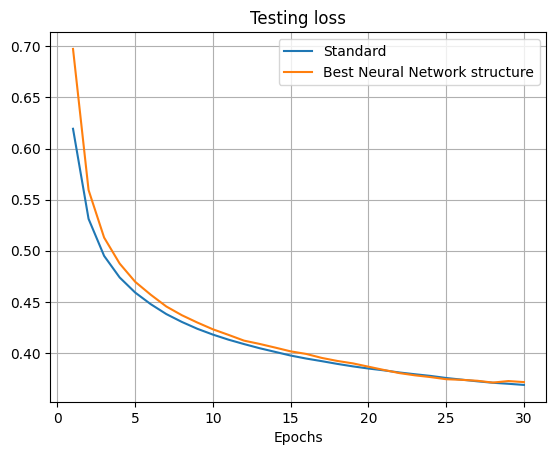

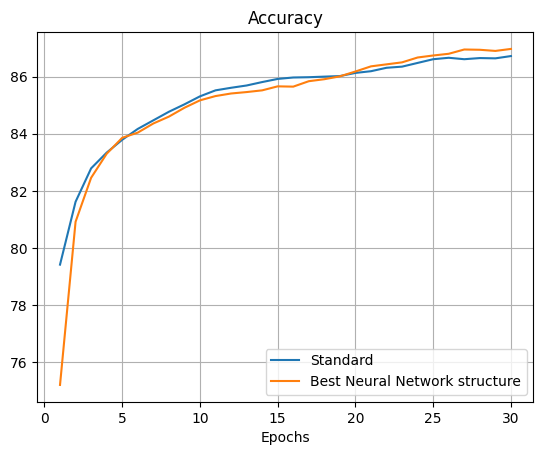

In [41]:
plot.plot_2_histories(
    std_test_loss_history, tun_test_loss_history, 'Testing loss', 'Standard', 'Best Neural Network structure')

plot.plot_2_histories(
    std_accuracy_history, tun_accuracy_history, 'Accuracy', 'Standard', 'Best Neural Network structure')